# Linear Regression 2.1 - Predicting Goal Difference (FIFA World Cup 2026)
## Part 1: Data checking, feature engineering and EDA (Rakebun Islam Lucky)

Goal difference = home goals - away goals. 104 matches, 8 explanatory variables, all known before kick-off.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load the data

In [3]:
matches = pd.read_csv('../data/matches_clean.csv', parse_dates=['date'])
players = pd.read_csv('../data/players_clean.csv')
team_info = pd.read_csv('../data/team_info.csv')

In [4]:
print(matches.shape, players.shape, team_info.shape)
matches.head()

(104, 21) (1039, 67) (48, 5)


,match_id,round,matchweek,date,kickoff_local,home_team,away_team,home_goals,away_goals,pens_home,...,goal_difference,total_goals,attendance,venue,referee,went_to_extra_time,went_to_pens,is_knockout,home_is_host,away_is_host
0,1,Group stage,1.0,2026-06-11,13:00,Mexico,South Africa,2,0,NaN,...,2,2,80824,Estadio Banorte,Wilton Sampaio,False,False,False,True,False
1,2,Group stage,1.0,2026-06-11,20:00,Korea Republic,Czechia,2,1,NaN,...,1,3,44985,Estadio Akron,Amin Omar,False,False,False,False,False
2,3,Group stage,1.0,2026-06-12,15:00,Canada,Bosnia–Herz,1,1,NaN,...,0,2,43002,BMO Field,Facundo Tello,False,False,False,True,False
3,4,Group stage,1.0,2026-06-12,18:00,USA,Paraguay,4,1,NaN,...,3,5,70492,SoFi Stadium,Danny Makkelie,False,False,False,True,False
4,5,Group stage,1.0,2026-06-13,12:00,Qatar,Switzerland,1,1,NaN,...,0,2,67966,Levi's Stadium,Said Martínez,False,False,False,False,False


## 4. Building the dataset

Each row is one match. All 8 variables are home team minus away team.
Form, points per game and rest days only use matches played **before** each match, so nothing from the match itself is used.

In [5]:
# team attributes known before the tournament
team_info = team_info.set_index('team')

# average squad age per team (squad name looks like 'us USA', so remove the code)
players['team'] = players['squad'].str.split(' ', n=1).str[1]
squad_age = players.groupby('team')['age'].mean()

# UEFA and CONMEBOL = traditionally strongest regions
strong = team_info['confederation'].isin(['UEFA', 'CONMEBOL']).astype(int)

In [6]:
# helper functions using a team's previous matches
def avg_goal_diff(history):
    if len(history) == 0:
        return 0
    return np.mean([h['gd'] for h in history])

def points_per_game(history):
    if len(history) == 0:
        return 0
    return np.mean([h['points'] for h in history])

In [7]:
def rest_days(history, today):
    if len(history) == 0:
        return None
    return (today - history[-1]['date']).days

def points(gd):
    if gd > 0:
        return 3
    elif gd == 0:
        return 1
    return 0

In [8]:
def make_row(m, hh, ah):
    h, a = m['home_team'], m['away_team']
    rest_h, rest_a = rest_days(hh, m['date']), rest_days(ah, m['date'])
    return {
        'match_id': m['match_id'], 'home_team': h, 'away_team': a,
        'x1_rank_diff': team_info.loc[a, 'fifa_rank'] - team_info.loc[h, 'fifa_rank'],
        'x2_appearances_diff': team_info.loc[h, 'wc_appearances'] - team_info.loc[a, 'wc_appearances'],
        'x3_host_advantage': int(m['home_is_host']) - int(m['away_is_host']),
        'x4_rest_days_diff': 0 if rest_h is None or rest_a is None else rest_h - rest_a,
        'x5_form_gd_diff': avg_goal_diff(hh) - avg_goal_diff(ah),
        'x6_points_per_game_diff': points_per_game(hh) - points_per_game(ah),
        'x7_squad_age_diff': round(squad_age[h] - squad_age[a], 3),
        'x8_strong_conf_diff': strong[h] - strong[a],
        'y_goal_difference': m['goal_difference'],
    }

In [9]:
history = {team: [] for team in team_info.index}
rows = []

for _, m in matches.sort_values(['date', 'match_id']).iterrows():
    h, a = m['home_team'], m['away_team']
    rows.append(make_row(m, history[h], history[a]))

    # update history AFTER the features are calculated
    gd = m['home_goals'] - m['away_goals']
    history[h].append({'gd': gd, 'points': points(gd), 'date': m['date']})
    history[a].append({'gd': -gd, 'points': points(-gd), 'date': m['date']})

In [10]:
df = pd.DataFrame(rows).sort_values('match_id').reset_index(drop=True)
features = [c for c in df.columns if c.startswith('x')]
print(df.shape, len(features), 'features')
print('missing values:', df.isna().sum().sum())

(104, 12) 8 features
missing values: 0


In [11]:
df.to_csv('../data/model_2_1.csv', index=False)
df.head()

,match_id,home_team,away_team,x1_rank_diff,x2_appearances_diff,x3_host_advantage,x4_rest_days_diff,x5_form_gd_diff,x6_points_per_game_diff,x7_squad_age_diff,x8_strong_conf_diff,y_goal_difference
0,1,Mexico,South Africa,46,14,1,0,0.0,0.0,0.768,0,2
1,2,Korea Republic,Czechia,22,2,0,0,0.0,0.0,-0.112,-1,1
2,3,Canada,Bosnia–Herz,44,1,1,0,0.0,0.0,0.190,-1,0
3,4,USA,Paraguay,25,3,1,0,0.0,0.0,-1.583,-1,3
4,5,Qatar,Switzerland,-34,-11,0,0,0.0,0.0,1.277,-1,0


## 5. Exploratory data analysis

In [12]:
df[features + ['y_goal_difference']].describe().round(2)

,x1_rank_diff,x2_appearances_diff,x3_host_advantage,x4_rest_days_diff,x5_form_gd_diff,x6_points_per_game_diff,x7_squad_age_diff,x8_strong_conf_diff,y_goal_difference
count,104.00,104.00,104.00,104.00,104.00,104.00,104.00,104.00,104.00
mean,8.24,2.74,0.07,0.12,0.24,0.08,-0.02,0.15,0.48
std,34.43,8.68,0.38,0.53,1.85,1.01,1.50,0.75,2.02
min,-78.00,-18.00,-1.00,-1.00,-6.00,-3.00,-3.34,-1.00,-4.00
25%,-15.25,-3.00,0.00,0.00,0.00,0.00,-1.03,0.00,-1.00
50%,7.00,2.00,0.00,0.00,0.00,0.00,-0.03,0.00,0.00
75%,33.00,10.00,0.00,0.00,1.00,0.50,1.09,1.00,2.00
max,79.00,21.00,1.00,3.00,5.00,3.00,2.96,1.00,6.00


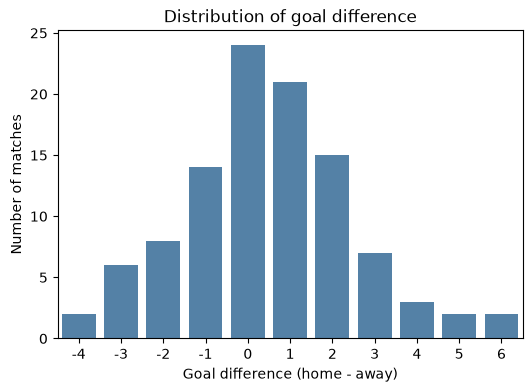

In [13]:
plt.figure(figsize=(6, 4))
sns.countplot(x='y_goal_difference', data=df, color='steelblue')
plt.title('Distribution of goal difference')
plt.xlabel('Goal difference (home - away)')
plt.ylabel('Number of matches')
plt.show()

In [14]:
print('Mean:', round(df['y_goal_difference'].mean(), 2))
print('Std:', round(df['y_goal_difference'].std(), 2))
print('Draws:', (df['y_goal_difference'] == 0).sum())

Mean: 0.48
Std: 2.02
Draws: 24


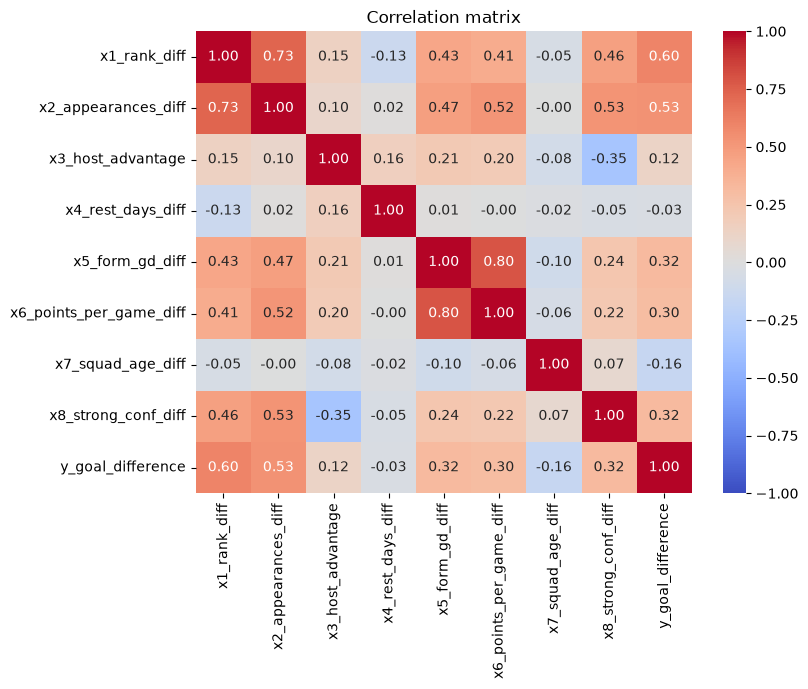

In [15]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[features + ['y_goal_difference']].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation matrix')
plt.show()

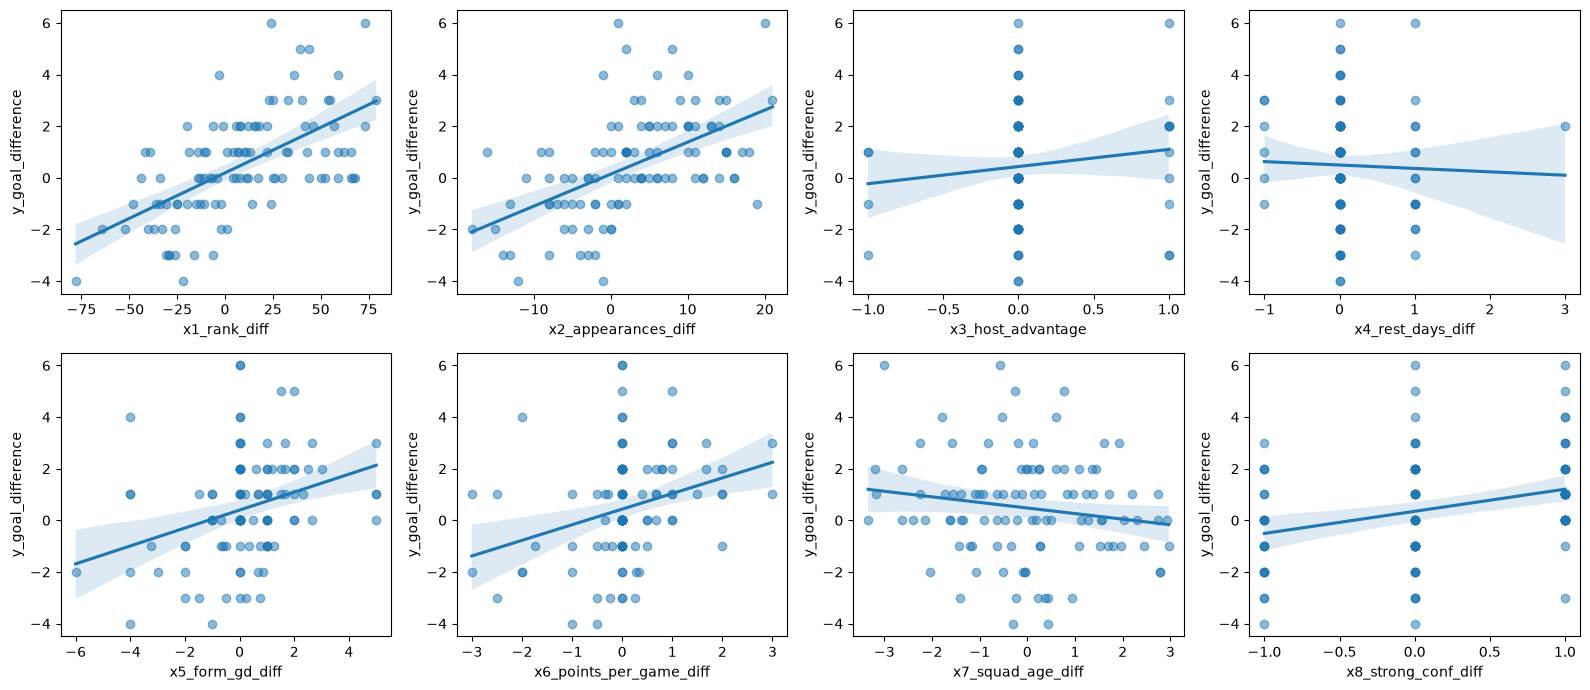

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, features):
    sns.regplot(x=col, y='y_goal_difference', data=df, ax=ax, scatter_kws={'alpha': 0.5})
plt.tight_layout()
plt.show()

Rank difference has the strongest relationship. But the effect seems to level off for very large rank gaps.
A gap of 10 places matters more at the top (rank 1 vs 11) than at the bottom (rank 70 vs 80),
so we also try the log of the rank ratio.

In [17]:
home_rank = df['home_team'].map(team_info['fifa_rank'])
away_rank = df['away_team'].map(team_info['fifa_rank'])
df['log_rank_ratio'] = np.log(away_rank / home_rank)

print('corr with rank diff:', round(df['x1_rank_diff'].corr(df['y_goal_difference']), 3))
print('corr with log rank ratio:', round(df['log_rank_ratio'].corr(df['y_goal_difference']), 3))

corr with rank diff: 0.6
corr with log rank ratio: 0.627


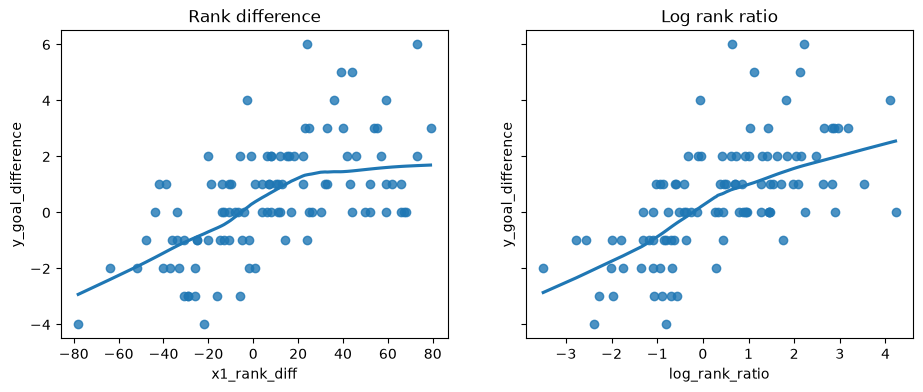

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
sns.regplot(x='x1_rank_diff', y='y_goal_difference', data=df, ax=axes[0], lowess=True)
sns.regplot(x='log_rank_ratio', y='y_goal_difference', data=df, ax=axes[1], lowess=True)
axes[0].set_title('Rank difference')
axes[1].set_title('Log rank ratio')
plt.show()

### Checking multicollinearity (VIF)

In [19]:
def vif(X):
    X = sm.add_constant(X)
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                     index=X.columns[1:]).round(2)

vif(df[features])

x1_rank_diff               2.45
x2_appearances_diff        2.81
x3_host_advantage          1.46
x4_rest_days_diff          1.09
x5_form_gd_diff            2.89
x6_points_per_game_diff    2.98
x7_squad_age_diff          1.03
x8_strong_conf_diff        1.92
dtype: float64

All VIF values are below 5, so multicollinearity is not a big problem.

## Part 2: Modelling and evaluation (Saimon Dahal)

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict, train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [21]:
df = pd.read_csv('../data/model_2_1.csv')
matches = pd.read_csv('../data/matches_clean.csv')
team_info = pd.read_csv('../data/team_info.csv').set_index('team')

In [22]:
features = [c for c in df.columns if c.startswith('x')]
y = df['y_goal_difference']

# log rank ratio (explained in Part 1, section 4)
df['log_rank_ratio'] = np.log(df['away_team'].map(team_info['fifa_rank']) /
                              df['home_team'].map(team_info['fifa_rank']))

## 5. Linear regression with all 8 features
### 5.1 Train/test split (80/20)

In [23]:
X = df[features]
y = df['y_goal_difference']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [24]:
model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

print('MAE :', round(mean_absolute_error(y_test, pred), 3))
print('RMSE:', round(np.sqrt(mean_squared_error(y_test, pred)), 3))
print('R2  :', round(r2_score(y_test, pred), 3))

MAE : 1.209
RMSE: 1.617
R2  : 0.25


### 5.2 10-fold cross-validation
With only 104 matches one split can be lucky or unlucky, so we use 10-fold cross-validation for all comparisons.

In [25]:
kf = KFold(n_splits=10, shuffle=True, random_state=1)

def cv_scores(X, y):
    # every match gets a prediction from a model that did not see it
    pred = cross_val_predict(LinearRegression(), X, y, cv=kf)
    return {'MAE': mean_absolute_error(y, pred),
            'RMSE': np.sqrt(mean_squared_error(y, pred)),
            'R2': r2_score(y, pred)}

In [26]:
results = {}
results['Baseline (always predict mean)'] = cv_scores(np.zeros((len(y), 1)), y)
results['All 8 features'] = cv_scores(df[features], y)
pd.DataFrame(results).T.round(3)

,MAE,RMSE,R2
Baseline (always predict mean),1.605,2.045,-0.031
All 8 features,1.397,1.762,0.235


The baseline model has no information, so it just predicts the average goal difference of the training folds. It is used as a reference point.

In [27]:
full = sm.OLS(y, sm.add_constant(df[features])).fit()
print(full.summary())

                            OLS Regression Results                            
Dep. Variable:      y_goal_difference   R-squared:                       0.400
Model:                            OLS   Adj. R-squared:                  0.349
Method:                 Least Squares   F-statistic:                     7.903
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           4.24e-08
Time:                        23:33:45   Log-Likelihood:                -193.87
No. Observations:                 104   AIC:                             405.7
Df Residuals:                      95   BIC:                             429.5
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

## 6. Improving the model
### 6.1 Log transform of rank

In [28]:
features_log = ['log_rank_ratio'] + features[1:]
results['All 8 features with log rank'] = cv_scores(df[features_log], y)
pd.DataFrame(results).T.round(3)

,MAE,RMSE,R2
Baseline (always predict mean),1.605,2.045,-0.031
All 8 features,1.397,1.762,0.235
All 8 features with log rank,1.345,1.734,0.259


### 6.2 Backward elimination
Remove the variable with the highest p-value, refit, and repeat until every p-value is below 0.05.

In [29]:
selected = features_log.copy()
while True:
    m = sm.OLS(y, sm.add_constant(df[selected])).fit()
    pvalues = m.pvalues.drop('const')
    worst = pvalues.idxmax()
    if pvalues[worst] < 0.05:
        break
    print(f'removing {worst} (p = {pvalues[worst]:.3f})')
    selected.remove(worst)

print('\nFinal variables:', selected)

removing x4_rest_days_diff (p = 0.855)
removing x5_form_gd_diff (p = 0.783)
removing x6_points_per_game_diff (p = 0.792)
removing x2_appearances_diff (p = 0.692)
removing x7_squad_age_diff (p = 0.498)
removing x8_strong_conf_diff (p = 0.494)
removing x3_host_advantage (p = 0.249)

Final variables: ['log_rank_ratio']


In [30]:
results['Final model (backward elimination)'] = cv_scores(df[selected], y)
comparison = pd.DataFrame(results).T.round(3)
comparison

,MAE,RMSE,R2
Baseline (always predict mean),1.605,2.045,-0.031
All 8 features,1.397,1.762,0.235
All 8 features with log rank,1.345,1.734,0.259
Final model (backward elimination),1.230,1.608,0.363


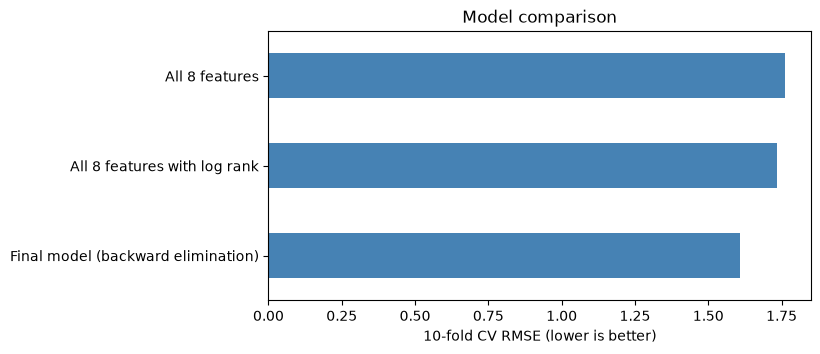

In [31]:
plot_data = comparison.drop('Baseline (always predict mean)')
plot_data['RMSE'].sort_values().plot(kind='barh', figsize=(7, 3.5), color='steelblue')
plt.xlabel('10-fold CV RMSE (lower is better)')
plt.title('Model comparison')
plt.show()

## 7. Final model

In [32]:
final = sm.OLS(y, sm.add_constant(df[selected])).fit()
print(final.summary())

                            OLS Regression Results                            
Dep. Variable:      y_goal_difference   R-squared:                       0.394
Model:                            OLS   Adj. R-squared:                  0.388
Method:                 Least Squares   F-statistic:                     66.23
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.02e-12
Time:                        23:33:45   Log-Likelihood:                -194.38
No. Observations:                 104   AIC:                             392.8
Df Residuals:                     102   BIC:                             398.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.1366      0.161      0.

### 7.1 Checking the assumptions

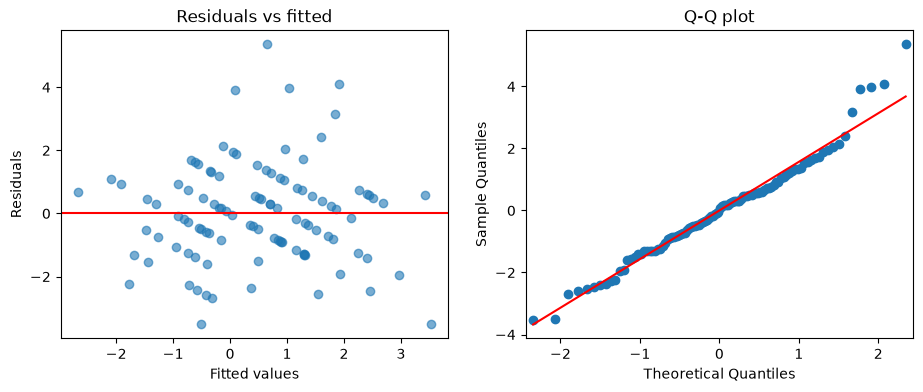

In [33]:
residuals = final.resid
fitted = final.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(fitted, residuals, alpha=0.6)
axes[0].axhline(0, color='red')
axes[0].set_xlabel('Fitted values'); axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs fitted')
sm.qqplot(residuals, line='s', ax=axes[1])
axes[1].set_title('Q-Q plot')
plt.show()

In [34]:
from scipy import stats
print('Shapiro-Wilk p-value:', round(stats.shapiro(residuals).pvalue, 3))

Shapiro-Wilk p-value: 0.045


### 7.2 Predicted vs actual (10-fold CV predictions)

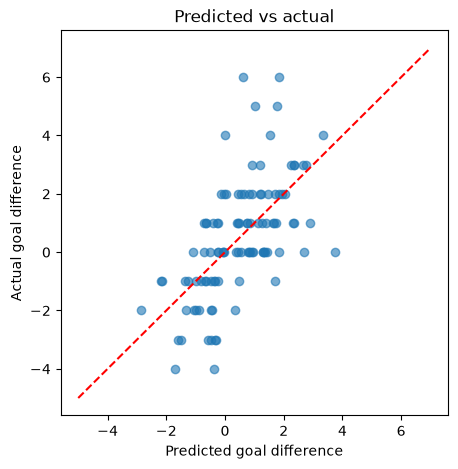

In [35]:
cv_pred = cross_val_predict(LinearRegression(), df[selected], y, cv=kf)

plt.figure(figsize=(5, 5))
plt.scatter(cv_pred, y, alpha=0.6)
plt.plot([-5, 7], [-5, 7], 'r--')
plt.xlabel('Predicted goal difference'); plt.ylabel('Actual goal difference')
plt.title('Predicted vs actual')
plt.show()

In [36]:
# how often does the model pick the right winner? (draws excluded)
not_draw = y != 0
correct = (np.sign(cv_pred[not_draw]) == np.sign(y[not_draw])).mean()
print(f'Correct winner: {correct:.0%} of {not_draw.sum()} matches')

Correct winner: 86% of 80 matches


### 7.3 Train on group stage, test on knockout matches
This is closer to real use, because the model only sees earlier matches.

In [37]:
group = matches['is_knockout'] == False
knock = matches['is_knockout'] == True

m = LinearRegression().fit(df.loc[group, selected], y[group])
p = m.predict(df.loc[knock, selected])
print('RMSE on knockout matches:', round(np.sqrt(mean_squared_error(y[knock], p)), 3))
print('MAE on knockout matches :', round(mean_absolute_error(y[knock], p), 3))

RMSE on knockout matches: 1.289
MAE on knockout matches : 0.972
